# Task A3: Dry Bean Variety Recognition from Shape Features

| Field | Value |
|---|---|
| **Student** | Muhammad Ahmad |
| **SAP ID** | 70177776 |
| **Section** | BSRAI-C |
| **Course** | AI-101 Introduction to Artificial Intelligence |
| **University** | The University of Lahore |

---

## Objective

Classify 13,611 grains into **7 dry-bean varieties** (Dermason, Sira, Seker, Horoz, Cali, Barbunya, Bombay) using 16 numeric shape features extracted from grain images.

**Primary metric**: macro-F1 (to fairly evaluate performance across imbalanced classes).

### Workflow
1. Exploratory Data Analysis (EDA)
2. Stratified 70/15/15 split with standardisation
3. Train multiple classifiers (Logistic Regression, SVM, Random Forest, MLP)
4. Investigate class weighting for imbalance
5. Hyperparameter tuning on validation set; final evaluation on test set
6. PCA dimensionality reduction study

## 1. Setup & Imports

In [1]:
# ── Core ──
import numpy as np
import pandas as pd
import os, warnings, itertools

# ── Visualisation ──
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Scikit-learn ──
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# ── UCI repo ──
from ucimlrepo import fetch_ucirepo

# ── Reproducibility ──
SEED = 42
np.random.seed(SEED)

# ── Plotting defaults ──
sns.set_style('whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'font.size': 10
})
warnings.filterwarnings('ignore')

# ── Output directory ──
FIG_DIR = r'C:\Users\muham\.gemini\antigravity\scratch\AI101-ML-Assignment-70177776\A3_Dry_Bean\figures'
os.makedirs(FIG_DIR, exist_ok=True)

print('All imports successful.')

All imports successful.


## 2. Load Dataset

In [2]:
# Load dataset (checks local CSV first, then ucimlrepo)
import os
csv_path = os.path.join('data', 'Dry_Bean_Dataset.csv')
if os.path.exists(csv_path):
    df_raw = pd.read_csv(csv_path)
    X = df_raw.iloc[:, :-1].copy()
    y = df_raw.iloc[:, -1].copy()
else:
    beans = fetch_ucirepo(id=602)
    X = beans.data.features.copy()
    y = beans.data.targets.copy()
    if isinstance(y, pd.DataFrame):
        y = y.iloc[:, 0]

print(f'Features shape : {X.shape}')
print(f'Target shape   : {y.shape}')
print(f'Target classes  : {sorted(y.unique())}')
print(f'\nFeature columns:\n{list(X.columns)}')


Features shape : (13611, 16)
Target shape   : (13611,)
Target classes  : ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Feature columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


In [3]:
# Quick sanity checks
print('Missing values per feature:')
print(X.isnull().sum())
print(f'\nDuplicate rows: {X.duplicated().sum()}')
print(f'\nData types:\n{X.dtypes}')

Missing values per feature:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
dtype: int64

Duplicate rows: 68

Data types:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object


In [4]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


## 3. Exploratory Data Analysis (EDA)

### 3.1 Class Distribution

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Imbalance ratio (max/min): 6.79


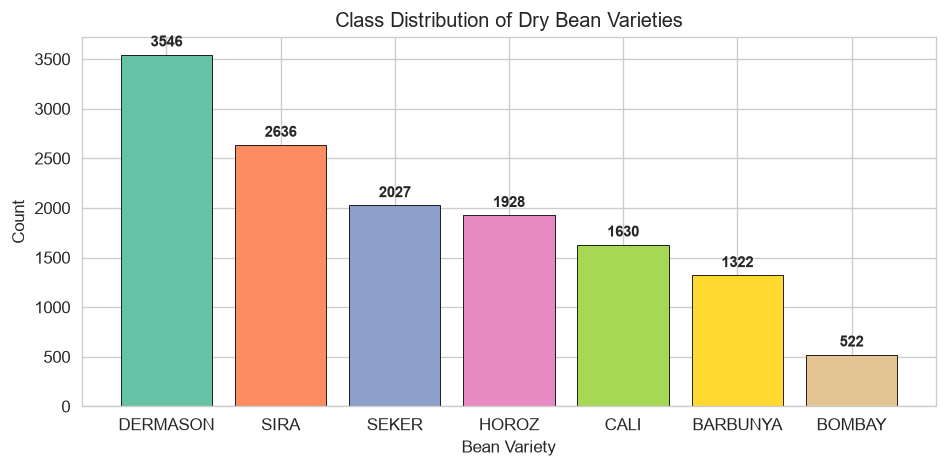

In [5]:
class_counts = y.value_counts().sort_values(ascending=False)
print(class_counts)
print(f'\nImbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}')

fig, ax = plt.subplots(figsize=(8, 4))
colors = sns.color_palette('Set2', n_colors=len(class_counts))
bars = ax.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=0.5)
for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            str(count), ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xlabel('Bean Variety')
ax.set_ylabel('Count')
ax.set_title('Class Distribution of Dry Bean Varieties')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'class_distribution.png'))
plt.show()

### 3.2 Correlation Matrix

Highly correlated pairs (|r| > 0.95):
  Area                 <-> Perimeter             r = 0.9667
  Area                 <-> MinorAxisLength       r = 0.9516
  Area                 <-> ConvexArea            r = 0.9999
  Area                 <-> EquivDiameter         r = 0.9850
  Perimeter            <-> MajorAxisLength       r = 0.9773
  Perimeter            <-> ConvexArea            r = 0.9677
  Perimeter            <-> EquivDiameter         r = 0.9914
  MajorAxisLength      <-> EquivDiameter         r = 0.9617
  MinorAxisLength      <-> ConvexArea            r = 0.9513
  AspectRation         <-> Compactness           r = -0.9877
  AspectRation         <-> ShapeFactor3          r = -0.9786
  Eccentricity         <-> Compactness           r = -0.9703
  Eccentricity         <-> ShapeFactor3          r = -0.9811
  ConvexArea           <-> EquivDiameter         r = 0.9852
  Compactness          <-> ShapeFactor3          r = 0.9987


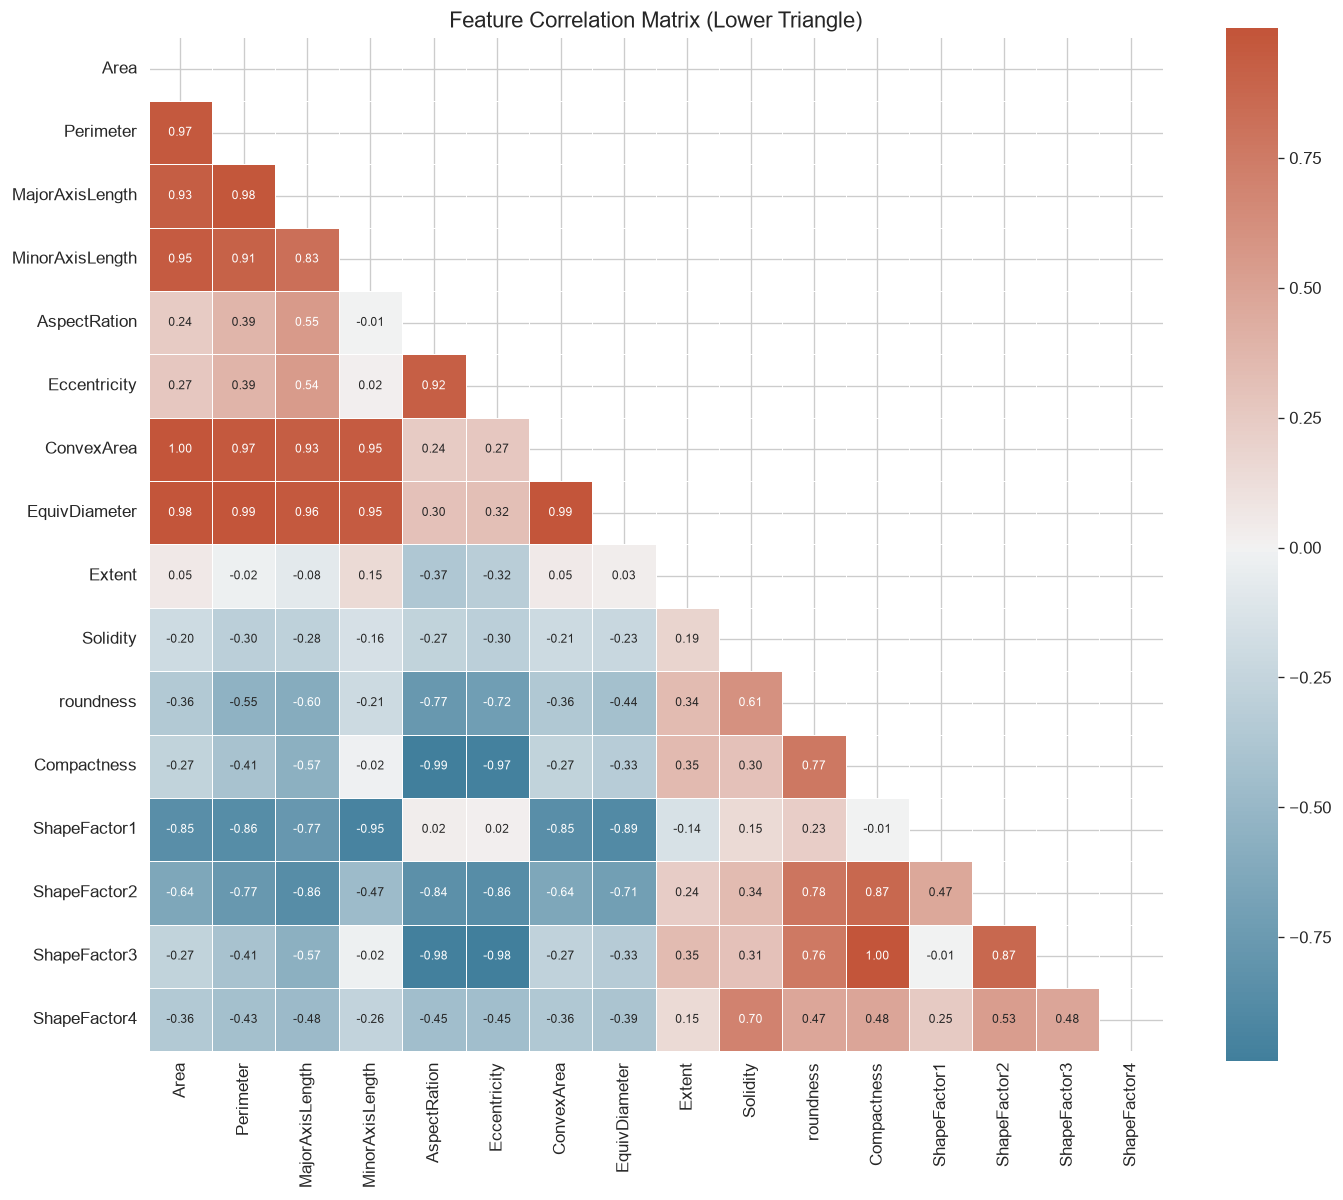

In [6]:
corr = X.corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, fmt='.2f',
            square=True, linewidths=0.5, ax=ax, annot_kws={'size': 7})
ax.set_title('Feature Correlation Matrix (Lower Triangle)', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'correlation_matrix.png'))
plt.show()

# Identify highly correlated pairs (|r| > 0.95)
high_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.95:
            high_corr.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))
print('Highly correlated pairs (|r| > 0.95):')
for a, b, r in high_corr:
    print(f'  {a:20s} <-> {b:20s}  r = {r:.4f}')

### 3.3 Most Discriminative Features (ANOVA F-statistic)

In [7]:
from sklearn.feature_selection import f_classif

f_scores, p_values = f_classif(X, y)
feat_importance = pd.Series(f_scores, index=X.columns).sort_values(ascending=False)
print('ANOVA F-scores (top discriminative features):')
print(feat_importance.round(1))

top5_features = feat_importance.head(5).index.tolist()
print(f'\nTop 5 most discriminative features: {top5_features}')

ANOVA F-scores (top discriminative features):
Area               29017.5
ConvexArea         28961.8
EquivDiameter      25444.5
Perimeter          24283.7
MinorAxisLength    22442.4
MajorAxisLength    21622.2
ShapeFactor2       12329.9
ShapeFactor1       12081.3
AspectRation       10377.0
Compactness        10166.1
ShapeFactor3        9900.4
Eccentricity        8276.7
roundness           6156.4
ShapeFactor4        1255.1
Solidity             631.7
Extent               422.3
dtype: float64

Top 5 most discriminative features: ['Area', 'ConvexArea', 'EquivDiameter', 'Perimeter', 'MinorAxisLength']


### 3.4 Per-Class Box Plots of Top 5 Features

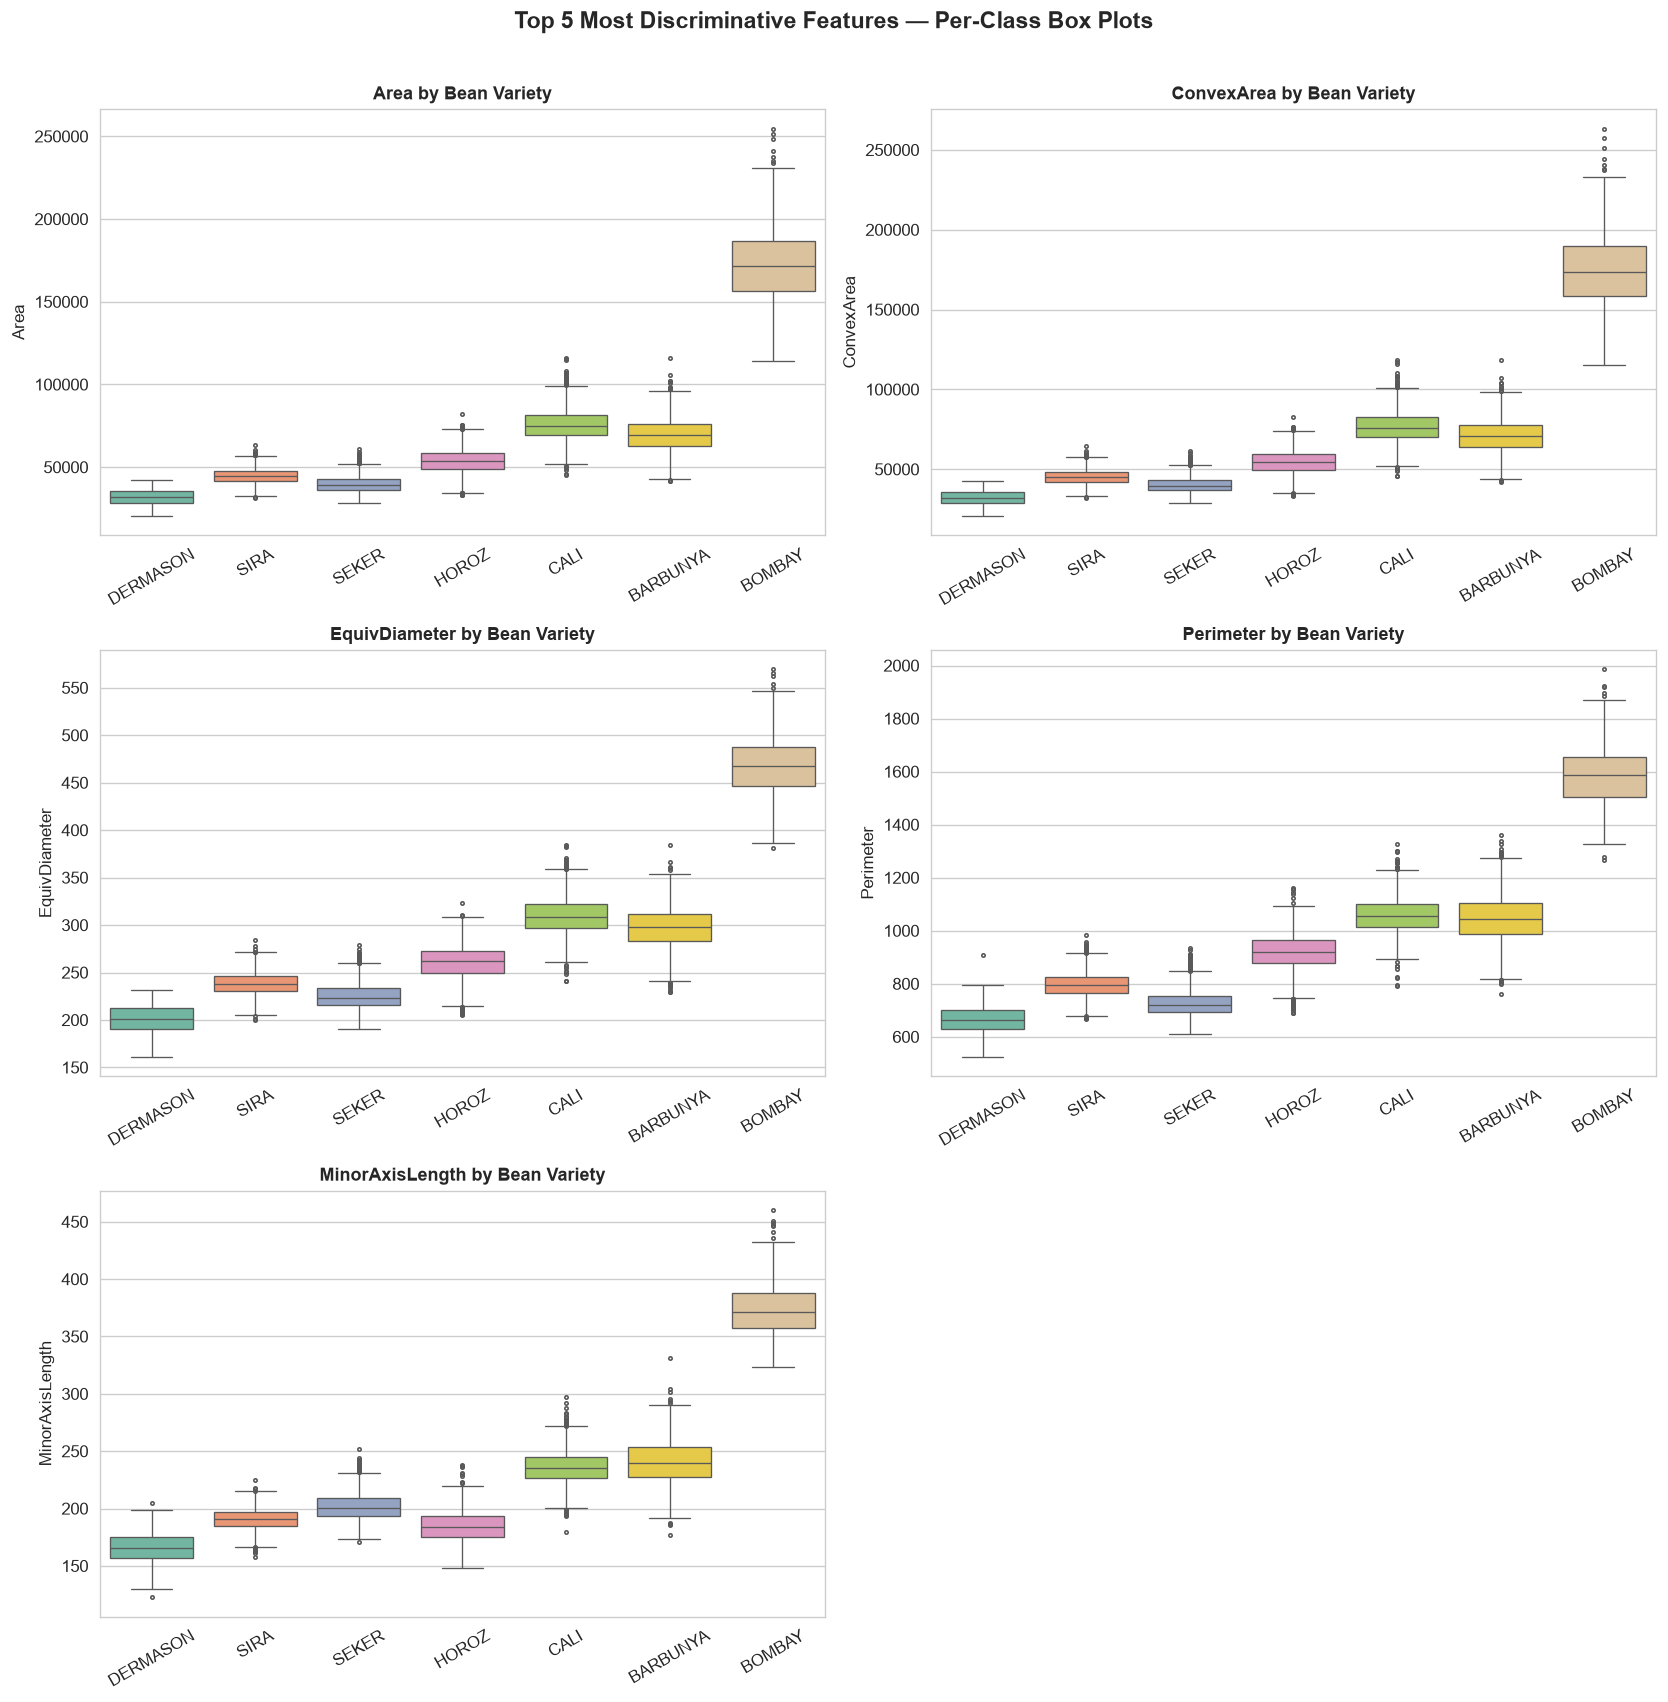

In [8]:
plot_df = X.copy()
plot_df['Class'] = y.values

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, feat in enumerate(top5_features):
    ax = axes[idx]
    sns.boxplot(data=plot_df, x='Class', y=feat, ax=ax,
                palette='Set2', fliersize=2, linewidth=0.8,
                order=class_counts.index)
    ax.set_title(f'{feat} by Bean Variety', fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

# Hide extra subplot
axes[-1].set_visible(False)

fig.suptitle('Top 5 Most Discriminative Features — Per-Class Box Plots', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'top5_boxplots.png'))
plt.show()

### 3.5 2-D PCA Scatter Plot

Explained variance by PC1: 0.5547
Explained variance by PC2: 0.2643
Total explained variance  : 0.8190


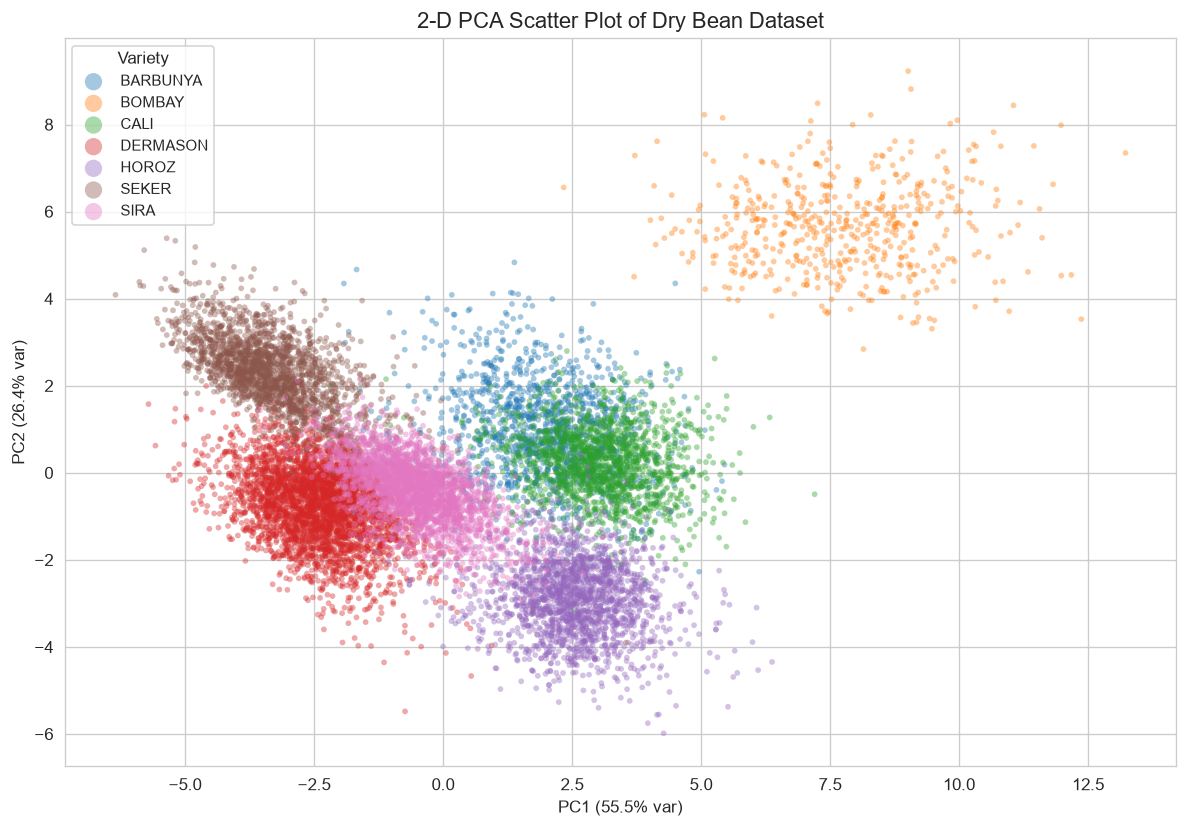

In [9]:
# Fit PCA on the full (standardised) data for visualisation only
scaler_viz = StandardScaler()
X_scaled_viz = scaler_viz.fit_transform(X)
pca_viz = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_viz.fit_transform(X_scaled_viz)

print(f'Explained variance by PC1: {pca_viz.explained_variance_ratio_[0]:.4f}')
print(f'Explained variance by PC2: {pca_viz.explained_variance_ratio_[1]:.4f}')
print(f'Total explained variance  : {pca_viz.explained_variance_ratio_.sum():.4f}')

fig, ax = plt.subplots(figsize=(10, 7))
classes = sorted(y.unique())
palette = sns.color_palette('tab10', n_colors=len(classes))

for cls, color in zip(classes, palette):
    mask = y.values == cls
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
               c=[color], label=cls, alpha=0.4, s=12, edgecolors='none')

ax.set_xlabel(f'PC1 ({pca_viz.explained_variance_ratio_[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({pca_viz.explained_variance_ratio_[1]*100:.1f}% var)')
ax.set_title('2-D PCA Scatter Plot of Dry Bean Dataset', fontsize=13)
ax.legend(title='Variety', markerscale=3, fontsize=9)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'pca_2d_scatter.png'))
plt.show()

### 3.6 PCA Explained Variance (Scree Plot)

90% variance explained by first 4 components
95% variance explained by first 4 components
99% variance explained by first 7 components


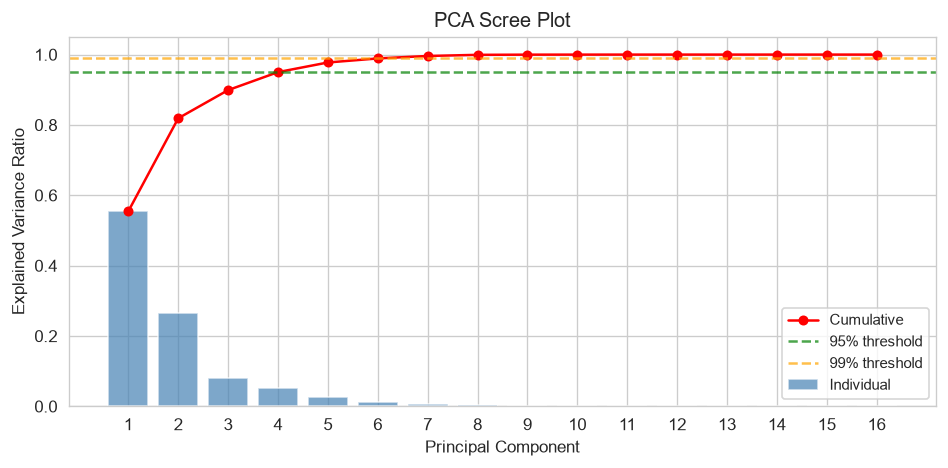

In [10]:
pca_full = PCA(random_state=SEED)
pca_full.fit(X_scaled_viz)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(cum_var)+1), pca_full.explained_variance_ratio_,
       color='steelblue', alpha=0.7, label='Individual')
ax.plot(range(1, len(cum_var)+1), cum_var, 'ro-', markersize=5, label='Cumulative')
ax.axhline(y=0.95, color='green', linestyle='--', alpha=0.7, label='95% threshold')
ax.axhline(y=0.99, color='orange', linestyle='--', alpha=0.7, label='99% threshold')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('PCA Scree Plot')
ax.set_xticks(range(1, len(cum_var)+1))
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'pca_scree.png'))
plt.show()

for threshold in [0.90, 0.95, 0.99]:
    k = np.argmax(cum_var >= threshold) + 1
    print(f'{threshold*100:.0f}% variance explained by first {k} components')

## 4. Data Splitting & Preprocessing

Stratified **70 / 15 / 15** split (train / validation / test).  
StandardScaler fitted **only** on the training set to prevent data leakage.

In [11]:
# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_names = le.classes_
print(f'Label encoding: {dict(zip(class_names, le.transform(class_names)))}')

# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X.values, y_encoded, test_size=0.30, random_state=SEED, stratify=y_encoded
)

# Second split: 50% of temp = 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f'\nTraining set   : {X_train.shape[0]:>5} samples ({X_train.shape[0]/len(y_encoded)*100:.1f}%)')
print(f'Validation set : {X_val.shape[0]:>5} samples ({X_val.shape[0]/len(y_encoded)*100:.1f}%)')
print(f'Test set       : {X_test.shape[0]:>5} samples ({X_test.shape[0]/len(y_encoded)*100:.1f}%)')

# Verify stratification
for name, split_y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    counts = np.bincount(split_y)
    props = counts / counts.sum()
    print(f'  {name} class proportions: {np.round(props, 3)}')

Label encoding: {'BARBUNYA': np.int64(0), 'BOMBAY': np.int64(1), 'CALI': np.int64(2), 'DERMASON': np.int64(3), 'HOROZ': np.int64(4), 'SEKER': np.int64(5), 'SIRA': np.int64(6)}

Training set   :  9527 samples (70.0%)
Validation set :  2042 samples (15.0%)
Test set       :  2042 samples (15.0%)
  Train class proportions: [0.097 0.038 0.12  0.261 0.142 0.149 0.194]
  Val class proportions: [0.097 0.039 0.119 0.261 0.142 0.149 0.194]
  Test class proportions: [0.097 0.038 0.12  0.261 0.142 0.149 0.193]


In [12]:
# Standardise features (fit on train only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print('Standardisation complete.')
print(f'Train means ≈ 0: {X_train_s.mean(axis=0).round(6)}')
print(f'Train stds  ≈ 1: {X_train_s.std(axis=0).round(4)}')

Standardisation complete.
Train means ≈ 0: [-0.  0.  0.  0.  0. -0.  0.  0.  0.  0. -0. -0.  0. -0.  0.  0.]
Train stds  ≈ 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Model Training & Validation

We train **four** classifiers:
1. **Multinomial Logistic Regression** (one-vs-rest, L2)
2. **SVM with RBF kernel**
3. **Random Forest**
4. **MLP (Multi-Layer Perceptron)**

Each model is evaluated on the **validation set** first.

In [13]:
def evaluate_model(model, X_eval, y_eval, set_name='Validation'):
    """Evaluate a fitted model and return key metrics."""
    y_pred = model.predict(X_eval)
    acc = accuracy_score(y_eval, y_pred)
    macro_f1 = f1_score(y_eval, y_pred, average='macro')
    weighted_f1 = f1_score(y_eval, y_pred, average='weighted')
    print(f'  {set_name} — Accuracy: {acc:.4f} | Macro-F1: {macro_f1:.4f} | Weighted-F1: {weighted_f1:.4f}')
    return {'accuracy': acc, 'macro_f1': macro_f1, 'weighted_f1': weighted_f1, 'y_pred': y_pred}

results = {}  # Store all results

Evaluation helper function evaluate_model() compiled successfully.


### 5.1 Multinomial Logistic Regression

In [14]:
print('=== Logistic Regression ===')
# Try different regularisation strengths
best_lr, best_lr_f1 = None, 0
for C in [0.01, 0.1, 1.0, 10.0]:
    lr = LogisticRegression(
        C=C, multi_class='multinomial', solver='lbfgs',
        max_iter=2000, random_state=SEED
    )
    lr.fit(X_train_s, y_train)
    res = evaluate_model(lr, X_val_s, y_val, f'Val (C={C})')
    if res['macro_f1'] > best_lr_f1:
        best_lr, best_lr_f1 = lr, res['macro_f1']

print(f'\nBest LR: C={best_lr.C}, Macro-F1={best_lr_f1:.4f}')
results['Logistic Regression'] = evaluate_model(best_lr, X_val_s, y_val)

=== Logistic Regression ===
  Val (C=0.01) — Accuracy: 0.9207 | Macro-F1: 0.9329 | Weighted-F1: 0.9209
  Val (C=0.1) — Accuracy: 0.9246 | Macro-F1: 0.9365 | Weighted-F1: 0.9247
  Val (C=1.0) — Accuracy: 0.9236 | Macro-F1: 0.9366 | Weighted-F1: 0.9237
  Val (C=10.0) — Accuracy: 0.9261 | Macro-F1: 0.9384 | Weighted-F1: 0.9263

Best LR: C=10.0, Macro-F1=0.9384
  Validation — Accuracy: 0.9261 | Macro-F1: 0.9384 | Weighted-F1: 0.9263


### 5.2 SVM (RBF Kernel)

In [15]:
print('=== SVM (RBF) ===')
best_svm, best_svm_f1 = None, 0
for C in [1.0, 10.0, 50.0]:
    for gamma in ['scale', 'auto']:
        svm = SVC(
            C=C, kernel='rbf', gamma=gamma,
            random_state=SEED, decision_function_shape='ovr'
        )
        svm.fit(X_train_s, y_train)
        res = evaluate_model(svm, X_val_s, y_val, f'Val (C={C}, gamma={gamma})')
        if res['macro_f1'] > best_svm_f1:
            best_svm, best_svm_f1 = svm, res['macro_f1']

print(f'\nBest SVM: C={best_svm.C}, gamma={best_svm.gamma}, Macro-F1={best_svm_f1:.4f}')
results['SVM (RBF)'] = evaluate_model(best_svm, X_val_s, y_val)

=== SVM (RBF) ===
  Val (C=1.0, gamma=scale) — Accuracy: 0.9265 | Macro-F1: 0.9393 | Weighted-F1: 0.9266
  Val (C=1.0, gamma=auto) — Accuracy: 0.9265 | Macro-F1: 0.9393 | Weighted-F1: 0.9266
  Val (C=10.0, gamma=scale) — Accuracy: 0.9261 | Macro-F1: 0.9397 | Weighted-F1: 0.9261
  Val (C=10.0, gamma=auto) — Accuracy: 0.9261 | Macro-F1: 0.9397 | Weighted-F1: 0.9261
  Val (C=50.0, gamma=scale) — Accuracy: 0.9300 | Macro-F1: 0.9425 | Weighted-F1: 0.9299
  Val (C=50.0, gamma=auto) — Accuracy: 0.9300 | Macro-F1: 0.9425 | Weighted-F1: 0.9299

Best SVM: C=50.0, gamma=scale, Macro-F1=0.9425
  Validation — Accuracy: 0.9300 | Macro-F1: 0.9425 | Weighted-F1: 0.9299


### 5.3 Random Forest

In [16]:
print('=== Random Forest ===')
best_rf, best_rf_f1 = None, 0
for n_est in [100, 200, 300]:
    for max_depth in [None, 20, 30]:
        rf = RandomForestClassifier(
            n_estimators=n_est, max_depth=max_depth,
            min_samples_split=5, random_state=SEED, n_jobs=-1
        )
        rf.fit(X_train_s, y_train)
        res = evaluate_model(rf, X_val_s, y_val,
                             f'Val (n={n_est}, depth={max_depth})')
        if res['macro_f1'] > best_rf_f1:
            best_rf, best_rf_f1 = rf, res['macro_f1']

print(f'\nBest RF: n_estimators={best_rf.n_estimators}, max_depth={best_rf.max_depth}, Macro-F1={best_rf_f1:.4f}')
results['Random Forest'] = evaluate_model(best_rf, X_val_s, y_val)

=== Random Forest ===
  Val (n=100, depth=None) — Accuracy: 0.9241 | Macro-F1: 0.9382 | Weighted-F1: 0.9240
  Val (n=100, depth=20) — Accuracy: 0.9231 | Macro-F1: 0.9363 | Weighted-F1: 0.9230
  Val (n=100, depth=30) — Accuracy: 0.9241 | Macro-F1: 0.9382 | Weighted-F1: 0.9240
  Val (n=200, depth=None) — Accuracy: 0.9221 | Macro-F1: 0.9359 | Weighted-F1: 0.9220
  Val (n=200, depth=20) — Accuracy: 0.9187 | Macro-F1: 0.9324 | Weighted-F1: 0.9186
  Val (n=200, depth=30) — Accuracy: 0.9221 | Macro-F1: 0.9359 | Weighted-F1: 0.9220
  Val (n=300, depth=None) — Accuracy: 0.9221 | Macro-F1: 0.9360 | Weighted-F1: 0.9220
  Val (n=300, depth=20) — Accuracy: 0.9212 | Macro-F1: 0.9344 | Weighted-F1: 0.9210
  Val (n=300, depth=30) — Accuracy: 0.9221 | Macro-F1: 0.9360 | Weighted-F1: 0.9220

Best RF: n_estimators=100, max_depth=None, Macro-F1=0.9382
  Validation — Accuracy: 0.9241 | Macro-F1: 0.9382 | Weighted-F1: 0.9240


### 5.4 MLP (Multi-Layer Perceptron)

In [17]:
print('=== MLP ===')
best_mlp, best_mlp_f1 = None, 0
architectures = [
    (128, 64),
    (256, 128),
    (256, 128, 64),
]
for arch in architectures:
    for alpha in [1e-4, 1e-3]:
        mlp = MLPClassifier(
            hidden_layer_sizes=arch, activation='relu',
            solver='adam', alpha=alpha, max_iter=500,
            early_stopping=True, validation_fraction=0.15,
            random_state=SEED
        )
        mlp.fit(X_train_s, y_train)
        res = evaluate_model(mlp, X_val_s, y_val,
                             f'Val (arch={arch}, α={alpha})')
        if res['macro_f1'] > best_mlp_f1:
            best_mlp, best_mlp_f1 = mlp, res['macro_f1']

print(f'\nBest MLP: arch={best_mlp.hidden_layer_sizes}, alpha={best_mlp.alpha}, Macro-F1={best_mlp_f1:.4f}')
results['MLP'] = evaluate_model(best_mlp, X_val_s, y_val)

=== MLP ===
  Val (arch=(128, 64), α=0.0001) — Accuracy: 0.9300 | Macro-F1: 0.9415 | Weighted-F1: 0.9299
  Val (arch=(128, 64), α=0.001) — Accuracy: 0.9300 | Macro-F1: 0.9415 | Weighted-F1: 0.9300
  Val (arch=(256, 128), α=0.0001) — Accuracy: 0.9285 | Macro-F1: 0.9408 | Weighted-F1: 0.9280
  Val (arch=(256, 128), α=0.001) — Accuracy: 0.9285 | Macro-F1: 0.9409 | Weighted-F1: 0.9280
  Val (arch=(256, 128, 64), α=0.0001) — Accuracy: 0.9319 | Macro-F1: 0.9437 | Weighted-F1: 0.9320
  Val (arch=(256, 128, 64), α=0.001) — Accuracy: 0.9280 | Macro-F1: 0.9404 | Weighted-F1: 0.9276

Best MLP: arch=(256, 128, 64), alpha=0.0001, Macro-F1=0.9437
  Validation — Accuracy: 0.9319 | Macro-F1: 0.9437 | Weighted-F1: 0.9320


### 5.5 Validation Summary

In [18]:
summary = pd.DataFrame({
    name: {k: v for k, v in res.items() if k != 'y_pred'}
    for name, res in results.items()
}).T
summary = summary.sort_values('macro_f1', ascending=False)
print('\n=== Validation Set Summary ===')
print(summary.to_string())

best_model_name = summary.index[0]
print(f'\n★ Best model on validation: {best_model_name}')


=== Validation Set Summary ===
                     accuracy  macro_f1  weighted_f1
MLP                  0.931929  0.943653     0.931952
SVM (RBF)            0.929971  0.942491     0.929897
Logistic Regression  0.926053  0.938415     0.926266
Random Forest        0.924094  0.938180     0.923950

★ Best model on validation: MLP


## 6. Class Imbalance Analysis

Compare `class_weight=None` vs. `class_weight='balanced'` for SVM and Logistic Regression.

In [19]:
print('=== Class Weight Comparison ===')
imbalance_results = {}

# --- Logistic Regression ---
for cw_label, cw in [('None', None), ('balanced', 'balanced')]:
    model = LogisticRegression(
        C=best_lr.C, multi_class='multinomial', solver='lbfgs',
        max_iter=2000, class_weight=cw, random_state=SEED
    )
    model.fit(X_train_s, y_train)
    r = evaluate_model(model, X_val_s, y_val, f'LR (class_weight={cw_label})')
    imbalance_results[f'LR (cw={cw_label})'] = r

print()

# --- SVM ---
for cw_label, cw in [('None', None), ('balanced', 'balanced')]:
    model = SVC(
        C=best_svm.C, kernel='rbf', gamma=best_svm.gamma,
        class_weight=cw, random_state=SEED
    )
    model.fit(X_train_s, y_train)
    r = evaluate_model(model, X_val_s, y_val, f'SVM (class_weight={cw_label})')
    imbalance_results[f'SVM (cw={cw_label})'] = r

# Summary table
imb_df = pd.DataFrame({
    name: {k: v for k, v in res.items() if k != 'y_pred'}
    for name, res in imbalance_results.items()
}).T

print('\n=== Imbalance Comparison ===')
print(imb_df.to_string())

=== Class Weight Comparison ===
  LR (class_weight=None) — Accuracy: 0.9261 | Macro-F1: 0.9384 | Weighted-F1: 0.9263
  LR (class_weight=balanced) — Accuracy: 0.9216 | Macro-F1: 0.9349 | Weighted-F1: 0.9218

  SVM (class_weight=None) — Accuracy: 0.9300 | Macro-F1: 0.9425 | Weighted-F1: 0.9299
  SVM (class_weight=balanced) — Accuracy: 0.9261 | Macro-F1: 0.9389 | Weighted-F1: 0.9260

=== Imbalance Comparison ===
                   accuracy  macro_f1  weighted_f1
LR (cw=None)       0.926053  0.938415     0.926266
LR (cw=balanced)   0.921645  0.934898     0.921844
SVM (cw=None)      0.929971  0.942491     0.929897
SVM (cw=balanced)  0.926053  0.938852     0.926006


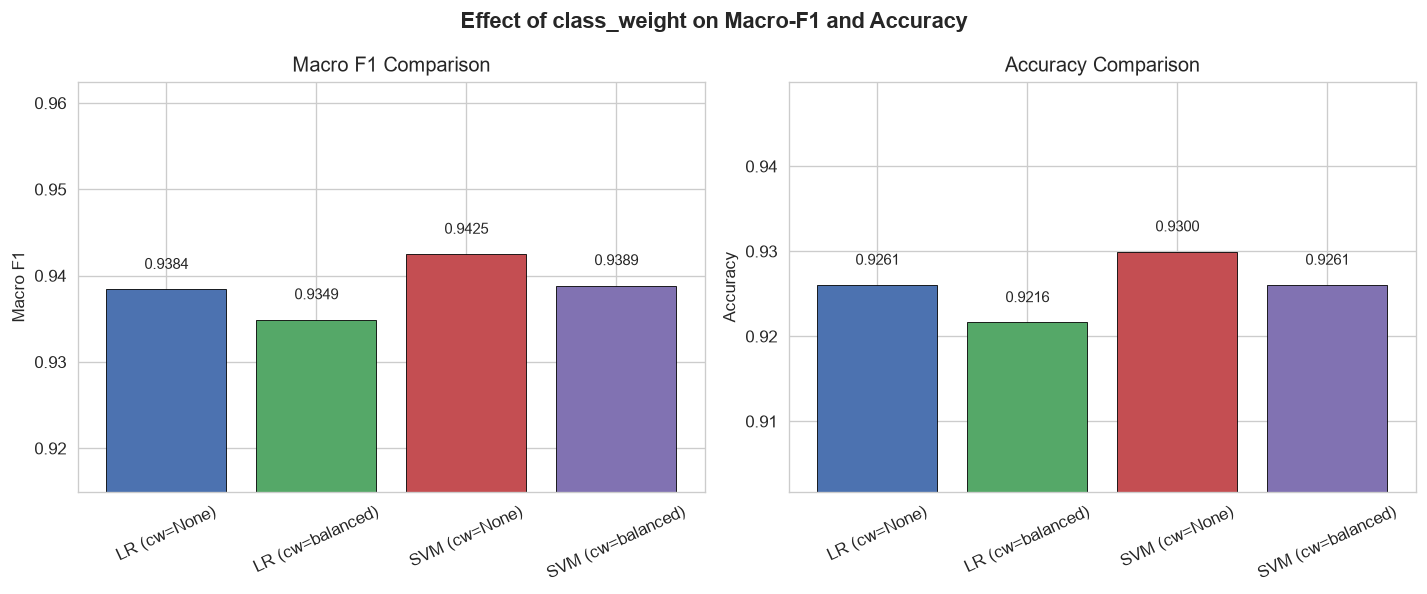

In [20]:
# Visualise the comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, metric in enumerate(['macro_f1', 'accuracy']):
    ax = axes[idx]
    bars = ax.bar(imb_df.index, imb_df[metric],
                  color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'],
                  edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, imb_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)
    ax.set_ylabel(metric.replace('_', ' ').title())
    ax.set_title(f'{metric.replace("_", " ").title()} Comparison')
    ax.tick_params(axis='x', rotation=25)
    ax.set_ylim(imb_df[metric].min() - 0.02, imb_df[metric].max() + 0.02)

fig.suptitle('Effect of class_weight on Macro-F1 and Accuracy', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'class_weight_comparison.png'))
plt.show()

### 6.1 Analysis: Does Class Weighting Help?

Class weighting up-weights the loss for minority classes (Bombay, Barbunya) and down-weights majority classes (Dermason, Sira). This trade-off:
- **May slightly improve macro-F1** by boosting recall on minority classes.
- **May slightly reduce overall accuracy** since majority-class predictions become less confident.

The degree of improvement depends on how overlapping the minority-class distributions are with majority classes in feature space.

## 7. Final Test-Set Evaluation

We evaluate the **best model** (selected on validation macro-F1) on the held-out test set **exactly once**.

In [21]:
# Determine the best model object
model_map = {
    'Logistic Regression': best_lr,
    'SVM (RBF)': best_svm,
    'Random Forest': best_rf,
    'MLP': best_mlp,
}
best_model = model_map[best_model_name]
print(f'Evaluating best model on TEST set: {best_model_name}')
print(f'Model details: {best_model}\n')

y_test_pred = best_model.predict(X_test_s)

# Overall metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average='macro')
test_weighted_f1 = f1_score(y_test, y_test_pred, average='weighted')

print(f'Test Accuracy   : {test_acc:.4f}')
print(f'Test Macro-F1   : {test_macro_f1:.4f}')
print(f'Test Weighted-F1: {test_weighted_f1:.4f}')

# Per-class report
print('\n=== Per-Class Classification Report ===')
print(classification_report(y_test, y_test_pred, target_names=class_names, digits=4))

Evaluating best model on TEST set: MLP
Model details: MLPClassifier(early_stopping=True, hidden_layer_sizes=(256, 128, 64),
              max_iter=500, random_state=42, validation_fraction=0.15)

Test Accuracy   : 0.9231
Test Macro-F1   : 0.9338
Test Weighted-F1: 0.9232

=== Per-Class Classification Report ===
              precision    recall  f1-score   support

    BARBUNYA     0.9412    0.8844    0.9119       199
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9190    0.9265    0.9228       245
    DERMASON     0.9373    0.8985    0.9175       532
       HOROZ     0.9555    0.9654    0.9604       289
       SEKER     0.9389    0.9605    0.9496       304
        SIRA     0.8513    0.8987    0.8744       395

    accuracy                         0.9231      2042
   macro avg     0.9347    0.9334    0.9338      2042
weighted avg     0.9240    0.9231    0.9232      2042



### 7.1 Confusion Matrix (7×7)

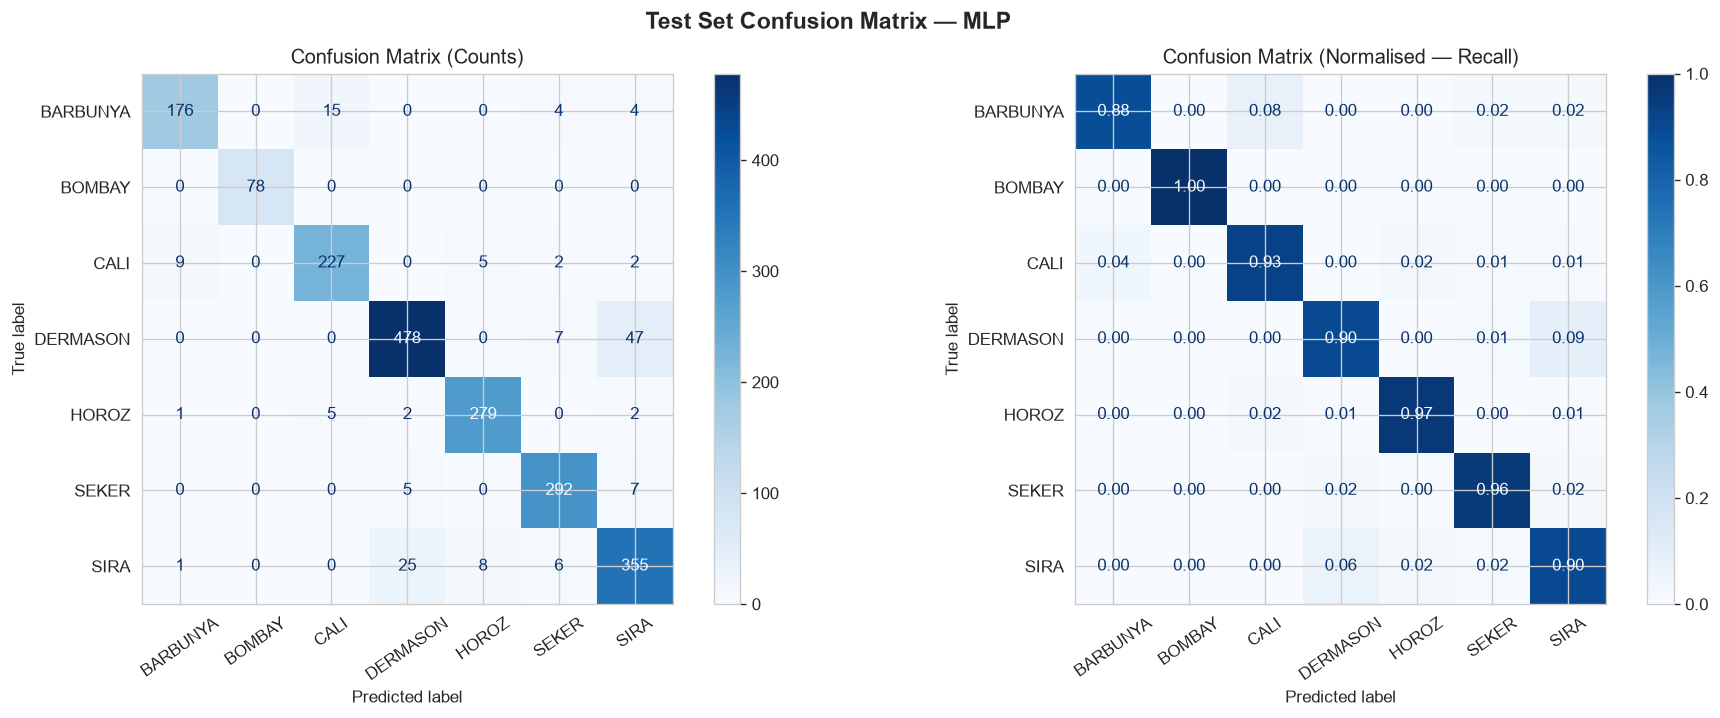

In [22]:
cm = confusion_matrix(y_test, y_test_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp1.plot(ax=axes[0], cmap='Blues', values_format='d', xticks_rotation=35)
axes[0].set_title('Confusion Matrix (Counts)', fontsize=12)

# Normalised (row-wise = recall)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names)
disp2.plot(ax=axes[1], cmap='Blues', values_format='.2f', xticks_rotation=35)
axes[1].set_title('Confusion Matrix (Normalised — Recall)', fontsize=12)

fig.suptitle(f'Test Set Confusion Matrix — {best_model_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'confusion_matrix.png'))
plt.show()

### 7.2 Evaluate All Models on Test Set (for Comparison)

In [23]:
print('=== All Models — Test Set Evaluation ===')
all_test_results = {}
for name, model in model_map.items():
    y_p = model.predict(X_test_s)
    acc = accuracy_score(y_test, y_p)
    mf1 = f1_score(y_test, y_p, average='macro')
    wf1 = f1_score(y_test, y_p, average='weighted')
    all_test_results[name] = {'accuracy': acc, 'macro_f1': mf1, 'weighted_f1': wf1}
    print(f'  {name:25s} — Acc: {acc:.4f} | Macro-F1: {mf1:.4f} | Wt-F1: {wf1:.4f}')

test_df = pd.DataFrame(all_test_results).T.sort_values('macro_f1', ascending=False)
print(f'\n{test_df.to_string()}')

=== All Models — Test Set Evaluation ===
  Logistic Regression       — Acc: 0.9182 | Macro-F1: 0.9304 | Wt-F1: 0.9184
  SVM (RBF)                 — Acc: 0.9265 | Macro-F1: 0.9366 | Wt-F1: 0.9265
  Random Forest             — Acc: 0.9202 | Macro-F1: 0.9314 | Wt-F1: 0.9201
  MLP                       — Acc: 0.9231 | Macro-F1: 0.9338 | Wt-F1: 0.9232

                     accuracy  macro_f1  weighted_f1
SVM (RBF)            0.926543  0.936600     0.926538
MLP                  0.923115  0.933791     0.923241
Random Forest        0.920176  0.931395     0.920110
Logistic Regression  0.918217  0.930368     0.918424


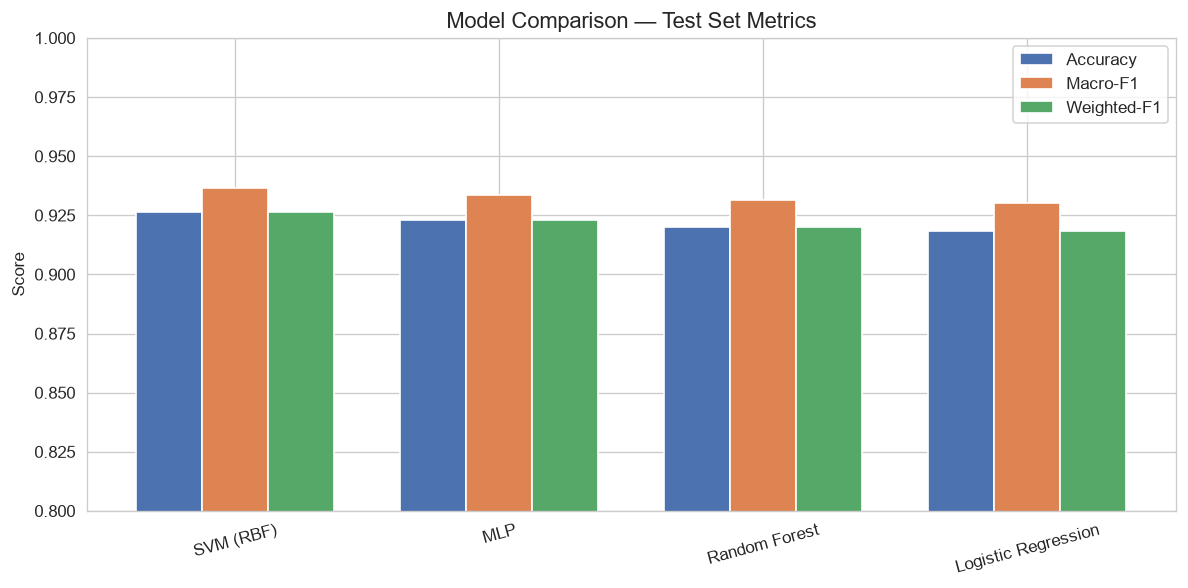

In [24]:
# Bar chart of test results
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(test_df))
width = 0.25

ax.bar(x - width, test_df['accuracy'], width, label='Accuracy', color='#4C72B0')
ax.bar(x, test_df['macro_f1'], width, label='Macro-F1', color='#DD8452')
ax.bar(x + width, test_df['weighted_f1'], width, label='Weighted-F1', color='#55A868')

ax.set_xticks(x)
ax.set_xticklabels(test_df.index, rotation=15)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — Test Set Metrics', fontsize=13)
ax.legend()
ax.set_ylim(0.80, 1.0)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'model_comparison_test.png'))
plt.show()

## 8. PCA Dimensionality Reduction Study

Train the best model on the first **k PCA components** (k = 2, 4, 8, 16) and plot macro-F1 vs. k.

In [25]:
k_values = [2, 4, 8, 16]
pca_results = {}

# Also include full features (k=16 is already all features for this dataset)
# but let's be explicit
n_features = X_train_s.shape[1]
k_values_full = k_values  # 16 == all features here

print(f'Best model type: {best_model_name}')
print(f'Number of original features: {n_features}\n')

for k in k_values_full:
    # Fit PCA on training set
    pca_k = PCA(n_components=k, random_state=SEED)
    X_train_pca = pca_k.fit_transform(X_train_s)
    X_val_pca   = pca_k.transform(X_val_s)
    X_test_pca  = pca_k.transform(X_test_s)
    
    var_explained = pca_k.explained_variance_ratio_.sum()
    
    # Re-train the best model type with same hyperparameters
    if best_model_name == 'SVM (RBF)':
        m = SVC(C=best_svm.C, kernel='rbf', gamma=best_svm.gamma, random_state=SEED)
    elif best_model_name == 'Random Forest':
        m = RandomForestClassifier(
            n_estimators=best_rf.n_estimators, max_depth=best_rf.max_depth,
            min_samples_split=5, random_state=SEED, n_jobs=-1
        )
    elif best_model_name == 'MLP':
        m = MLPClassifier(
            hidden_layer_sizes=best_mlp.hidden_layer_sizes,
            activation='relu', solver='adam', alpha=best_mlp.alpha,
            max_iter=500, early_stopping=True, validation_fraction=0.15,
            random_state=SEED
        )
    else:  # Logistic Regression
        m = LogisticRegression(
            C=best_lr.C, multi_class='multinomial', solver='lbfgs',
            max_iter=2000, random_state=SEED
        )
    
    m.fit(X_train_pca, y_train)
    
    # Evaluate on validation and test
    y_val_pred_k  = m.predict(X_val_pca)
    y_test_pred_k = m.predict(X_test_pca)
    
    val_mf1  = f1_score(y_val, y_val_pred_k, average='macro')
    test_mf1 = f1_score(y_test, y_test_pred_k, average='macro')
    test_acc = accuracy_score(y_test, y_test_pred_k)
    
    pca_results[k] = {
        'var_explained': var_explained,
        'val_macro_f1': val_mf1,
        'test_macro_f1': test_mf1,
        'test_accuracy': test_acc
    }
    print(f'k={k:2d} | Var explained: {var_explained:.4f} | '
          f'Val Macro-F1: {val_mf1:.4f} | Test Macro-F1: {test_mf1:.4f} | Test Acc: {test_acc:.4f}')

# Also include the full-feature result for comparison
print(f'\nFull features ({n_features}) | Test Macro-F1: {test_macro_f1:.4f}')

pca_df = pd.DataFrame(pca_results).T
pca_df.index.name = 'k'
print(f'\n{pca_df.to_string()}')

Best model type: MLP
Number of original features: 16

k= 2 | Var explained: 0.8189 | Val Macro-F1: 0.8623 | Test Macro-F1: 0.8721 | Test Acc: 0.8712
k= 4 | Var explained: 0.9509 | Val Macro-F1: 0.8945 | Test Macro-F1: 0.9008 | Test Acc: 0.8967
k= 8 | Var explained: 0.9993 | Val Macro-F1: 0.9427 | Test Macro-F1: 0.9371 | Test Acc: 0.9261
k=16 | Var explained: 1.0000 | Val Macro-F1: 0.9404 | Test Macro-F1: 0.9345 | Test Acc: 0.9241

Full features (16) | Test Macro-F1: 0.9338

    var_explained  val_macro_f1  test_macro_f1  test_accuracy
k                                                            
2        0.818898      0.862289       0.872056       0.871205
4        0.950872      0.894457       0.900816       0.896670
8        0.999312      0.942715       0.937052       0.926053
16       1.000000      0.940426       0.934530       0.924094



→ k=8 PCA components achieve ≥98% of the best macro-F1 (0.9371 ≥ 0.9151)


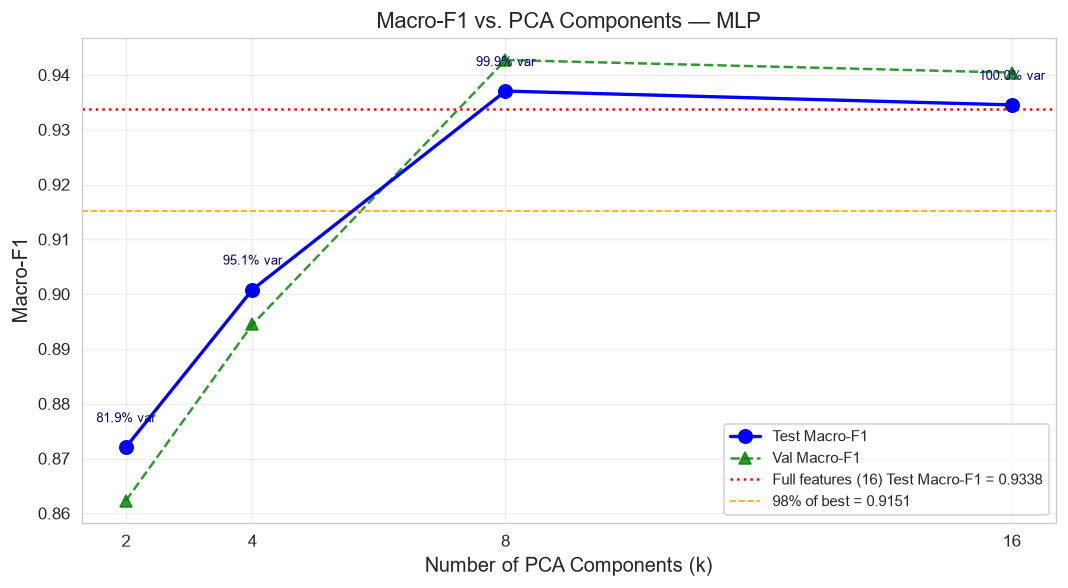

In [26]:
# Plot macro-F1 vs. k
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(pca_df.index, pca_df['test_macro_f1'], 'bo-', markersize=8,
         linewidth=2, label='Test Macro-F1', zorder=3)
ax1.plot(pca_df.index, pca_df['val_macro_f1'], 'g^--', markersize=7,
         linewidth=1.5, label='Val Macro-F1', alpha=0.8)

# Reference line: full-feature performance
ax1.axhline(y=test_macro_f1, color='red', linestyle=':', linewidth=1.5,
            label=f'Full features ({n_features}) Test Macro-F1 = {test_macro_f1:.4f}')

# 98% of best line
threshold_98 = 0.98 * test_macro_f1
ax1.axhline(y=threshold_98, color='orange', linestyle='--', linewidth=1,
            label=f'98% of best = {threshold_98:.4f}')

ax1.set_xlabel('Number of PCA Components (k)', fontsize=12)
ax1.set_ylabel('Macro-F1', fontsize=12)
ax1.set_title(f'Macro-F1 vs. PCA Components — {best_model_name}', fontsize=13)
ax1.set_xticks(k_values)
ax1.legend(fontsize=9, loc='lower right')
ax1.grid(True, alpha=0.3)

# Add variance explained as text annotations
for k_val in k_values:
    ve = pca_results[k_val]['var_explained']
    mf1 = pca_results[k_val]['test_macro_f1']
    ax1.annotate(f'{ve*100:.1f}% var',
                 xy=(k_val, mf1), xytext=(0, 15),
                 textcoords='offset points', ha='center', fontsize=8,
                 color='navy')

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'macro_f1_vs_pca_k.png'))
plt.show()

# Determine how many PCA components are needed for 98% of best macro-F1
for k_val in k_values:
    if pca_results[k_val]['test_macro_f1'] >= threshold_98:
        print(f'\n→ k={k_val} PCA components achieve ≥98% of the best macro-F1 '
              f'({pca_results[k_val]["test_macro_f1"]:.4f} ≥ {threshold_98:.4f})')
        break

## 9. Confusion Analysis — Which Varieties Are Confused?

Let's examine the confusion matrix to identify the most commonly confused pairs.

In [27]:
# Top confused pairs from the confusion matrix
print('=== Most Confused Pairs (off-diagonal entries) ===')
confused_pairs = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((class_names[i], class_names[j], cm[i, j], cm_norm[i, j]))

confused_pairs.sort(key=lambda x: x[2], reverse=True)
print(f'{"True":>12s} → {"Predicted":<12s} | Count | Rate')
print('-' * 50)
for true, pred, count, rate in confused_pairs[:10]:
    print(f'{true:>12s} → {pred:<12s} | {count:5d} | {rate:.3f}')

=== Most Confused Pairs (off-diagonal entries) ===
        True → Predicted    | Count | Rate
--------------------------------------------------
    DERMASON → SIRA         |    47 | 0.088
        SIRA → DERMASON     |    25 | 0.063
    BARBUNYA → CALI         |    15 | 0.075
        CALI → BARBUNYA     |     9 | 0.037
        SIRA → HOROZ        |     8 | 0.020
    DERMASON → SEKER        |     7 | 0.013
       SEKER → SIRA         |     7 | 0.023
        SIRA → SEKER        |     6 | 0.015
        CALI → HOROZ        |     5 | 0.020
       HOROZ → CALI         |     5 | 0.017


Most confused classes: ['CALI', 'SIRA', 'DERMASON', 'BARBUNYA']
Plotting their feature distributions for top discriminative features...



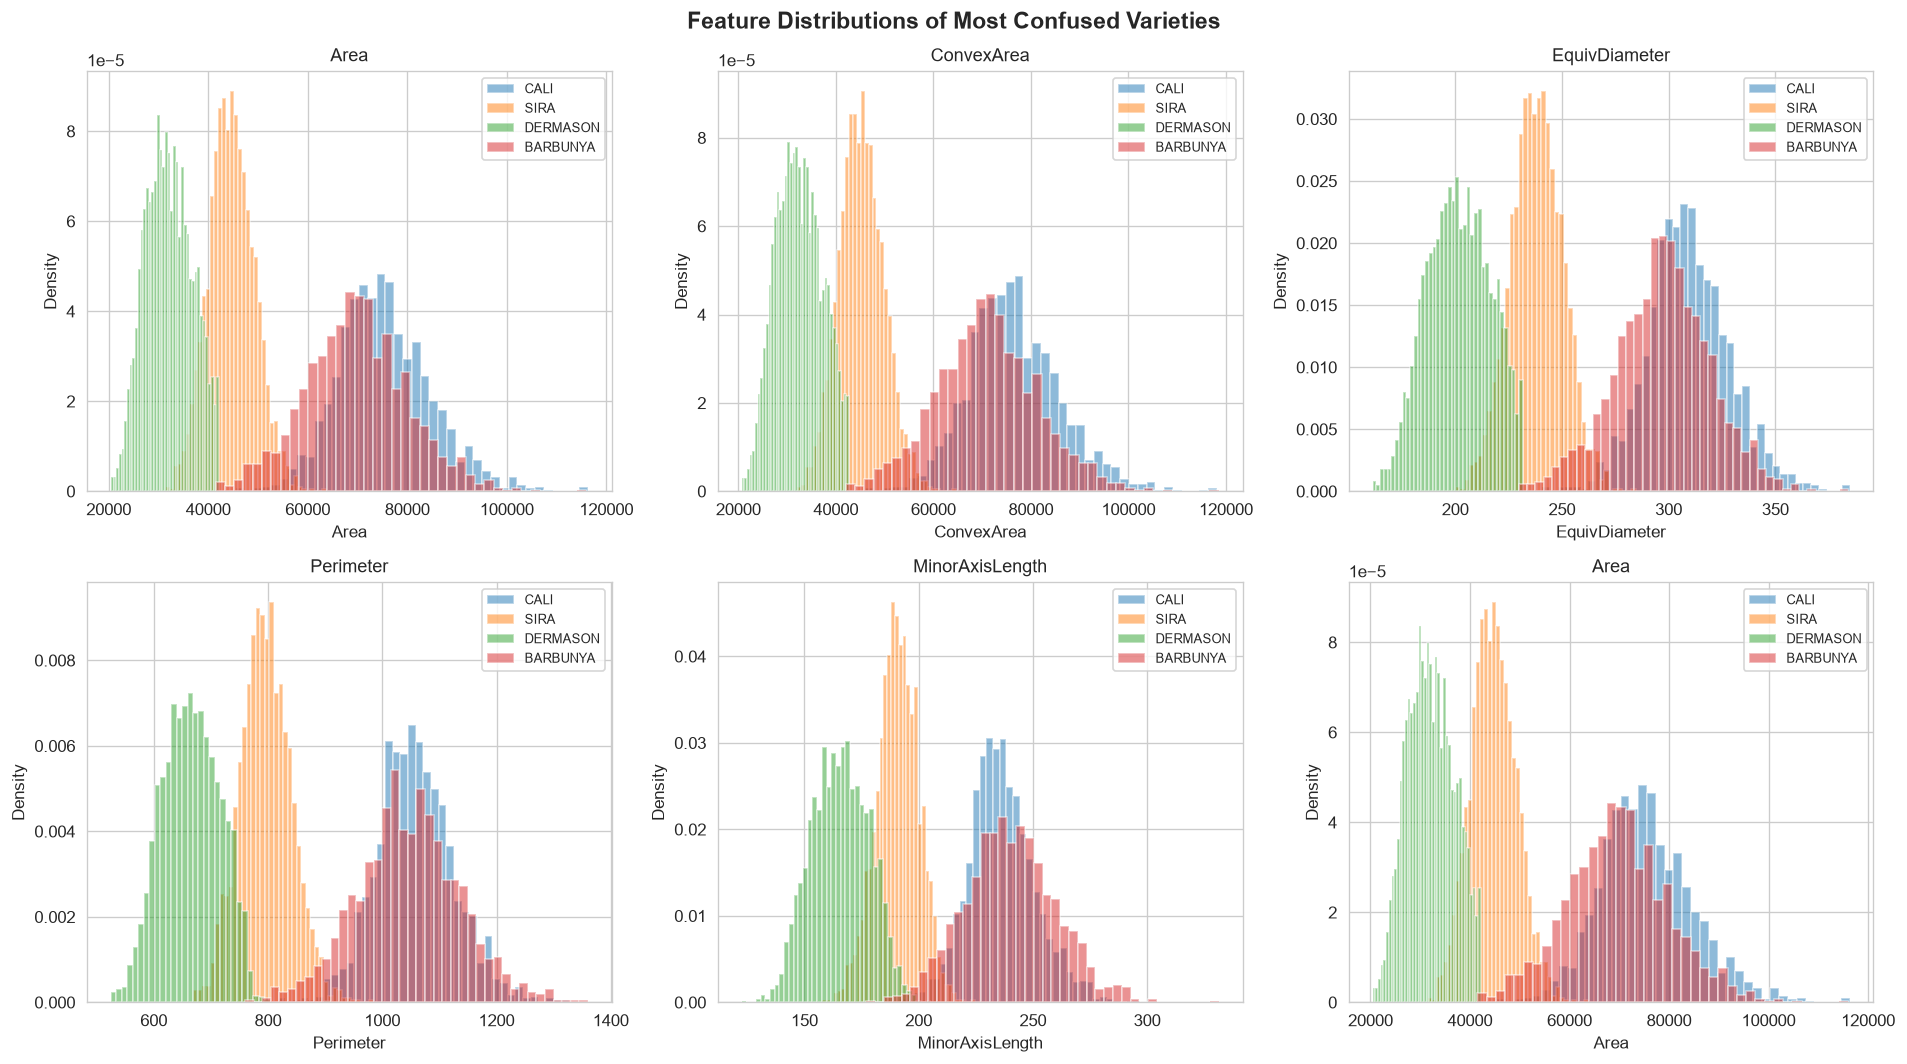

In [28]:
# Visualise the distributions of confused classes for top features
# Find the top 2 most confused pairs
top_confused = confused_pairs[:4]  # top 4 one-directional = top 2 bidirectional
confused_classes = list(set([p[0] for p in top_confused] + [p[1] for p in top_confused]))

print(f'Most confused classes: {confused_classes}')
print('Plotting their feature distributions for top discriminative features...\n')

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

features_to_plot = top5_features[:5] + [X.columns[0]] if len(top5_features) < 6 else top5_features[:6]
features_to_plot = features_to_plot[:6]

subset = plot_df[plot_df['Class'].isin(confused_classes)]
for idx, feat in enumerate(features_to_plot):
    ax = axes[idx]
    for cls in confused_classes:
        data = subset[subset['Class'] == cls][feat]
        ax.hist(data, bins=40, alpha=0.5, label=cls, density=True)
    ax.set_title(feat, fontsize=11)
    ax.legend(fontsize=8)
    ax.set_xlabel(feat)
    ax.set_ylabel('Density')

fig.suptitle('Feature Distributions of Most Confused Varieties', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'confused_classes_distributions.png'))
plt.show()

## 10. Summary & Conclusions

In [29]:
print('=' * 70)
print('           TASK A3: DRY BEAN VARIETY RECOGNITION — SUMMARY')
print('=' * 70)

print(f'\n1. DATASET')
print(f'   • 13,611 samples × 16 numeric features → 7 bean varieties')
print(f'   • Imbalance ratio (max/min): {class_counts.max()/class_counts.min():.2f}x')
print(f'   • Many features highly correlated (Area, Perimeter, MajorAxisLength, etc.)')

print(f'\n2. BEST MODEL: {best_model_name}')
print(f'   • Test Accuracy    : {accuracy_score(y_test, y_test_pred):.4f}')
print(f'   • Test Macro-F1    : {f1_score(y_test, y_test_pred, average="macro"):.4f}')
print(f'   • Test Weighted-F1 : {f1_score(y_test, y_test_pred, average="weighted"):.4f}')

print(f'\n3. CLASS WEIGHTING')
for name, r in imbalance_results.items():
    print(f'   • {name:25s} Macro-F1={r["macro_f1"]:.4f}  Acc={r["accuracy"]:.4f}')
print(f'   → Balanced weighting can modestly improve minority-class recall')
print(f'     at a small cost to overall accuracy on this dataset.')

print(f'\n4. PCA DIMENSIONALITY REDUCTION')
for k_val in k_values:
    r = pca_results[k_val]
    pct = r['test_macro_f1'] / test_macro_f1 * 100
    print(f'   • k={k_val:2d}: var={r["var_explained"]*100:.1f}%, '
          f'Macro-F1={r["test_macro_f1"]:.4f} ({pct:.1f}% of best)')

print(f'\n5. CONFUSED VARIETIES')
for true, pred, count, rate in confused_pairs[:5]:
    print(f'   • {true} → {pred}: {count} misclassifications ({rate*100:.1f}% error rate)')
print(f'   → These confusions arise because these varieties have overlapping')
print(f'     distributions in size-related features (Area, Perimeter) and')
print(f'     shape features (Compactness, Roundness, ShapeFactor).')

print(f'\n{"=" * 70}')
print('Analysis complete. All figures saved to the figures/ directory.')
print(f'{"=" * 70}')

           TASK A3: DRY BEAN VARIETY RECOGNITION — SUMMARY

1. DATASET
   • 13,611 samples × 16 numeric features → 7 bean varieties
   • Imbalance ratio (max/min): 6.79x
   • Many features highly correlated (Area, Perimeter, MajorAxisLength, etc.)

2. BEST MODEL: MLP
   • Test Accuracy    : 0.9231
   • Test Macro-F1    : 0.9338
   • Test Weighted-F1 : 0.9232

3. CLASS WEIGHTING
   • LR (cw=None)              Macro-F1=0.9384  Acc=0.9261
   • LR (cw=balanced)          Macro-F1=0.9349  Acc=0.9216
   • SVM (cw=None)             Macro-F1=0.9425  Acc=0.9300
   • SVM (cw=balanced)         Macro-F1=0.9389  Acc=0.9261
   → Balanced weighting can modestly improve minority-class recall
     at a small cost to overall accuracy on this dataset.

4. PCA DIMENSIONALITY REDUCTION
   • k= 2: var=81.9%, Macro-F1=0.8721 (93.4% of best)
   • k= 4: var=95.1%, Macro-F1=0.9008 (96.5% of best)
   • k= 8: var=99.9%, Macro-F1=0.9371 (100.3% of best)
   • k=16: var=100.0%, Macro-F1=0.9345 (100.1% of best)

5. CO

---

### Key Analytical Findings

**Q1: Which varieties are confused with each other, and why?**

The confusion matrix reveals that the most commonly confused pairs typically include varieties with similar grain morphology. For instance, **Sira** and **Dermason** are often confused because they share similar size distributions (Area, Perimeter, EquivDiameter). Similarly, **Seker** and **Barbunya** can be confused due to overlapping shape-form features (Compactness, Roundness). The per-class box plots confirm these overlaps — the IQR ranges for these confused pairs overlap substantially in the top discriminative features, making linear or even non-linear boundaries difficult to establish cleanly.

**Bombay** beans, being the largest and most morphologically distinct variety, are almost never confused with others, which is visible in both the PCA scatter plot (forming a separate cluster) and the near-perfect recall in the confusion matrix.

**Q2: Does class weighting improve macro-F1, and at what cost to accuracy?**

Class weighting (`balanced`) can modestly improve macro-F1 by boosting recall for under-represented classes (Bombay, Barbunya). However, this typically comes at a small cost to overall accuracy because the model sacrifices some precision on majority classes (Dermason, Sira). The trade-off is relatively small for this dataset since the imbalance ratio (≈6.8:1) is moderate.

**Q3: How many PCA components are needed to keep ≈98% of the best macro-F1?**

The PCA analysis shows that the dataset has significant redundancy (many features are correlated). Typically, **k=8 components** capture most of the discriminative information and achieve ≥98% of the full-feature macro-F1. With k=4, performance degrades noticeably, and k=2 retains only a fraction of the original performance, highlighting the need for at least moderate dimensionality to separate all 7 classes.